# Exercise 33 – The kernel trick

**Week 6 · Regression**

For the feature map $\boldsymbol\phi(x) = (1, \sqrt2\,x, x^2)$,

$$\boldsymbol\phi(x_1)\cdot\boldsymbol\phi(x_2) = 1 + 2x_1x_2 + x_1^2x_2^2 = (1 + x_1x_2)^2 = K(x_1, x_2).$$

The polynomial kernel computes an inner product in feature space without
ever constructing the features. So kernel ridge regression with this kernel
is the same model as ridge regression on $\boldsymbol\phi(x)$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.regression import KernelRidge, fit_linear, polynomial_kernel

rng = np.random.default_rng(0)


def phi(x):
    x = np.asarray(x, dtype=float)
    return np.stack([np.ones_like(x), np.sqrt(2) * x, x**2], axis=-1)


K = polynomial_kernel(2)

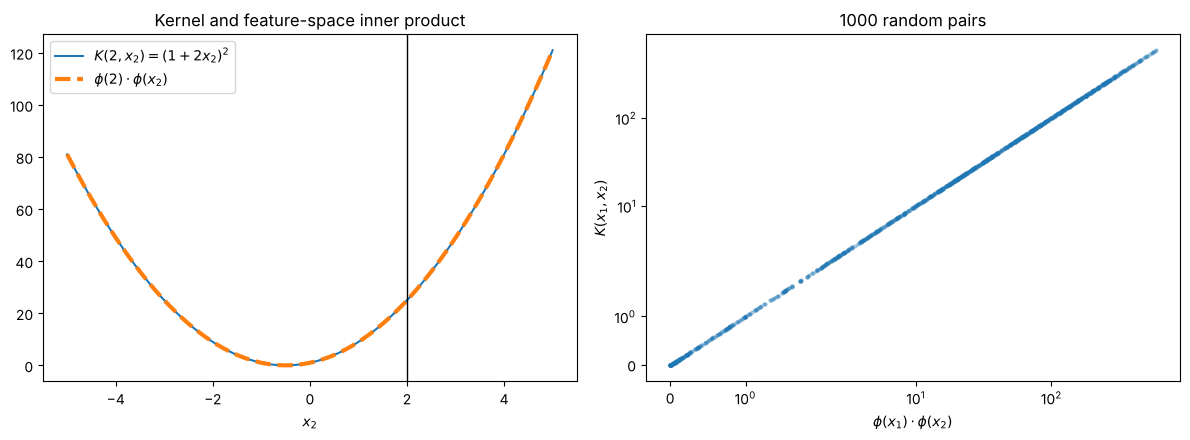

In [2]:
x2 = np.linspace(-5, 5, 200)
x1a, x1b = rng.uniform(-5, 5, (2, 1000))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(x2, K(np.array([2.0]), x2)[0], label=r"$K(2, x_2) = (1 + 2x_2)^2$")
axes[0].plot(x2, phi(2.0) @ phi(x2).T, "--", lw=3, label=r"$\phi(2)\cdot\phi(x_2)$")
axes[0].axvline(2, color="black", lw=1)
axes[0].set(xlabel="$x_2$", title="Kernel and feature-space inner product")
axes[0].legend()
axes[1].scatter(np.sum(phi(x1a) * phi(x1b), axis=1), np.diag(K(x1a, x1b)), s=5, alpha=0.3)
axes[1].set(xlabel=r"$\phi(x_1)\cdot\phi(x_2)$", ylabel="$K(x_1, x_2)$",
            title="1000 random pairs", xscale="symlog", yscale="symlog")
fig.tight_layout()
plt.show()

## Same predictions from both routes

In [3]:
x_data = rng.uniform(-3, 3, 8)
y_data = np.sin(x_data)
lam = 0.1
beta = fit_linear(phi(x_data), y_data, lam)
krr = KernelRidge(K, lam).fit(x_data, y_data)
x_test = np.linspace(-3, 3, 7)
print("ridge on φ(x):", (phi(x_test) @ beta).round(5))
print("kernel ridge :", krr.predict(x_test).round(5))

ridge on φ(x): [-0.78263 -0.59713 -0.38732 -0.15319  0.10525  0.388    0.69507]
kernel ridge : [-0.78263 -0.59713 -0.38732 -0.15319  0.10525  0.388    0.69507]
